In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# 1.1 y 1.2 Configurar entorno y definir parámetros
fs = 1000       # Frecuencia de muestreo
fc = 50         # Frecuencia portadora
t_desc = 0.2    # Duración de la señal
t = np.arange(0, t_desc, 1/fs)
L = len(t)

# 1.5 Función para añadir Ruido Gaussiano Blanco Aditivo (AWGN)
def add_awgn(signal, snr_db):
    signal_power = np.mean(signal**2)
    snr_linear = 10**(snr_db / 10)
    noise_power = signal_power / snr_linear
    noise = np.random.normal(0, np.sqrt(noise_power), len(signal))
    return signal + noise

# 1.3 Programar generadores de señales
def generate_ask():
    # ASK: Varía la amplitud (1.0 o 0.3)
    amp = 1.0 if np.random.randint(0, 2) == 1 else 0.3
    return amp * np.sin(2 * np.pi * fc * t)

def generate_fsk():
    # FSK: Varía la frecuencia
    f = fc if np.random.randint(0, 2) == 1 else fc * 2
    return np.sin(2 * np.pi * f * t)

def generate_psk():
    # PSK (BPSK): Varía la fase (0 o 180 grados)
    phase = 0 if np.random.randint(0, 2) == 1 else np.pi
    return np.sin(2 * np.pi * fc * t + phase)

def generate_qam16():
    # 16-QAM: Combina amplitud y fase
    amplitudes = [0.25, 0.5, 0.75, 1.0]
    phases = [0, np.pi/2, np.pi, 3*np.pi/2]
    amp = np.random.choice(amplitudes)
    phase = np.random.choice(phases)
    return amp * np.sin(2 * np.pi * fc * t + phase)

# 1.4 Generar el conjunto de datos (1,000 muestras por modulación)
X, y = [], []
muestras_por_clase = 1000

for _ in range(muestras_por_clase):
    X.append(generate_ask()); y.append(0)
    X.append(generate_fsk()); y.append(1)
    X.append(generate_psk()); y.append(2)
    X.append(generate_qam16()); y.append(3)

X = np.array(X)
y = np.array(y)

# Añadir ruido base para simular el canal
X_ruido = np.array([add_awgn(sig, 15) for sig in X])

# 1.6 Separación de datos: Entrenamiento (80%) y Prueba (20%)
X_ruido = X_ruido.reshape(-1, L, 1) # Redimensionar para CNN 1D
X_train, X_test, y_train, y_test = train_test_split(X_ruido, y, test_size=0.2, random_state=42)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.6244 - loss: 0.8114 - val_accuracy: 0.6850 - val_loss: 0.6488
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.6703 - loss: 0.6472 - val_accuracy: 0.6475 - val_loss: 0.6718
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.6809 - loss: 0.6313 - val_accuracy: 0.6925 - val_loss: 0.6153
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7013 - loss: 0.6053 - val_accuracy: 0.6700 - val_loss: 0.6169
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7312 - loss: 0.5859 - val_accuracy: 0.6925 - val_loss: 0.5783
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7466 - loss: 0.5467 - val_accuracy: 0.7075 - val_loss: 0.5852
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7622 - loss: 0.5226 - val_accuracy: 0.6888 - val_loss: 0.5631
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7678 - loss: 0.5119 - val_accu

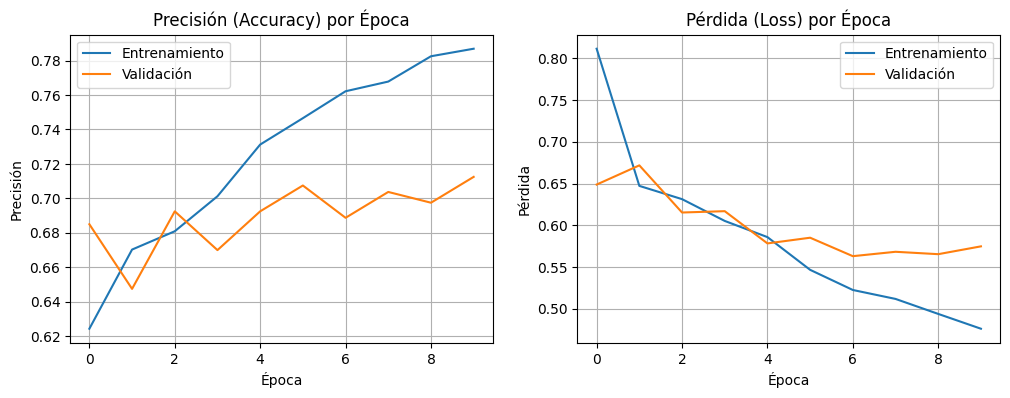

Modelo guardado correctamente.


In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, Flatten, Dense

# 2.2 Diseñar el modelo 1D-CNN
model = Sequential([
    Input(shape=(L, 1)),                             # Capa de entrada con la longitud L de la señal
    Conv1D(filters=16, kernel_size=5, activation='relu'), # Primera capa convolucional
    Conv1D(filters=32, kernel_size=5, activation='relu'), # Segunda capa convolucional
    Flatten(),                                       # Aplana los mapas de características
    Dense(64, activation='relu'),                    # Capa oculta densa
    Dense(4, activation='softmax')                   # Capa de salida: 4 neuronas (ASK, FSK, PSK, QAM)
])

# 2.3 Compilar el modelo
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', # Pérdida para clasificación multiclase con etiquetas enteras (0, 1, 2, 3)
    metrics=['accuracy']
)

# 2.4 Entrenar el modelo con el 80% de entrenamiento y validar con el 20%
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test, y_test)
)

# Graficar el monitoreo de precisión y pérdida (útil para tu reporte)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history['accuracy'], label='Entrenamiento')
ax1.plot(history.history['val_accuracy'], label='Validación')
ax1.set_title('Precisión (Accuracy) por Época')
ax1.set_xlabel('Época')
ax1.set_ylabel('Precisión')
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['loss'], label='Entrenamiento')
ax2.plot(history.history['val_loss'], label='Validación')
ax2.set_title('Pérdida (Loss) por Época')
ax2.set_xlabel('Época')
ax2.set_ylabel('Pérdida')
ax2.legend()
ax2.grid(True)

plt.show()

# 2.5 Guardar el modelo entrenado
model.save('detective_senales_model.keras')
print("Modelo guardado correctamente.")

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 3.1 Matriz de Confusión
y_pred = np.argmax(model.predict(X_test), axis=1)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ASK', 'FSK', 'PSK', 'QAM'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión (SNR = 15dB)')
plt.show()

# 3.2 y 3.3 Prueba de estrés y Gráfica de rendimiento
snr_levels = range(-10, 21, 2)
accuracies = []

for snr in snr_levels:
    X_stress = np.array([add_awgn(sig, snr) for sig in X])
    X_stress = X_stress.reshape(-1, L, 1)
    _, acc = model.evaluate(X_stress, y, verbose=0)
    accuracies.append(acc)

plt.figure()
plt.plot(snr_levels, accuracies, marker='o', color='red')
plt.xlabel('Relación Señal-Ruido (SNR en dB)')
plt.ylabel('Precisión (Accuracy)')
plt.title('Robustez del Modelo ante el Ruido AWGN')
plt.grid(True)
plt.axvline(0, color='gray', linestyle='--')
plt.show()